# UTS Machine Learning - Task 3: Clustering Segmentasi Pelanggan

Data: 120.000 pelanggan, tanpa label. Notebook ini mengikuti poin a-g Task 3 pada ketentuan UTS.

| Poin | Ketentuan | Bagian |
|---|---|---|
| a | Preprocessing (skala, skew, kompositional, kategorik, missing, outlier) | 3 |
| b | Seleksi fitur dengan bukti | 4 |
| c | Minimal 3 metode | 5 |
| d | Jumlah cluster, minimal 2 kriteria | 6 |
| e | Stabilitas (bootstrap/subsampling, ARI antar-run) | 7 |
| f | Nama segmen, profil, satu aksi pemasaran per segmen | 9 |
| g | Anomali berlabel -1 | 8 |
| - | `cluster.csv` | 10 |

## 0. Persiapan

Semua parameter ada di satu cell. Seed dan versi library dicetak untuk reproduksi. Data dibaca dari `clustering.csv.gz` atau `data_uts_ml.zip` di folder kerja; jika tidak ada dan berjalan di Colab, file zip diunggah.

In [2]:
import os, re, time, zipfile, warnings, platform
from itertools import combinations

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import scipy, sklearn

from scipy.cluster import hierarchy
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import IsolationForest
from sklearn.metrics import (silhouette_score, davies_bouldin_score,
                             calinski_harabasz_score, adjusted_rand_score)

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

# ---------------- Parameter (ubah di sini bila perlu) ----------------
SEED = 42
WINS_P = 0.005            # winsorizing 0,5% di tiap ekor
R_MAX = 0.80              # pasangan fitur dengan |korelasi| >= ini dianggap redundan
ETA2_MIN = 0.02           # fitur relevan jika cluster menjelaskan >= 2% variansnya
K_PILOT = (4, 6, 8)       # K pilot untuk seleksi fitur
SEL_N = 40000             # ukuran sampel untuk seleksi fitur
PCA_VAR = 0.99            # varians PCA yang dipertahankan
K_RANGE = range(2, 13)    # K yang dicoba
K_MIN = 3                 # K minimum agar segmen tetap bisa ditindaklanjuti
STAB_MIN = 0.80           # ARI antar-run minimum untuk K kandidat
MIN_SHARE = 1.0           # cluster terkecil minimum (% pelanggan)
B_BOOT = 10               # jumlah run subsampling untuk stabilitas
FRAC_BOOT = 0.80          # porsi data per run subsampling
CAP_GMM = 30000           # ukuran data latih GMM pada sweep/bootstrap
CAP_AGG = 10000           # ukuran sampel Agglomerative (Ward)
N_EVAL = 10000            # ukuran sampel untuk silhouette/DB/CH
ANOMALY_FRAC = 0.01       # porsi pelanggan yang ditandai anomali (-1)
K_OVERRIDE = None         # isi angka untuk memaksa K tertentu
METODE_OVERRIDE = None    # "KMeans", "GMM", atau "Agglomerative"

np.random.seed(SEED)
print("Python", platform.python_version())
for lib in (np, pd, scipy, sklearn, matplotlib, sns):
    print(f"{lib.__name__:12s}", lib.__version__)
print("SEED =", SEED)

Python 3.13.18
numpy        2.4.6
pandas       2.2.3
scipy        1.16.3
sklearn      1.6.1
matplotlib   3.10.0
seaborn      0.13.2
SEED = 42


In [3]:
def baca_clustering():
    for p in ("clustering.csv.gz", "data/clustering.csv.gz"):
        if os.path.exists(p):
            return pd.read_csv(p)
    for p in ("data_uts_ml.zip", "data/data_uts_ml.zip"):
        if os.path.exists(p):
            return baca_zip(p)
    from google.colab import files          # cadangan: unggah manual di Colab
    nama = next(n for n in files.upload() if n.lower().endswith(".zip"))
    return baca_zip(nama)

def baca_zip(path):
    with zipfile.ZipFile(path) as z:
        isi = next(n for n in z.namelist() if n.endswith("clustering.csv.gz"))
        return pd.read_csv(z.open(isi), compression="gzip")

clustering = baca_clustering()
print("Dataset terbaca:", clustering.shape)

Saving data_uts_ml.zip to data_uts_ml.zip
Dataset terbaca: (120000, 60)


## 1. Audit Data

Memeriksa missing value, duplikasi, identifier, dan kewajaran nilai. Kolom dikelompokkan menurut jenisnya agar preprocessing bisa dibedakan.

In [4]:
df = clustering

# Kelompok kolom
KOL_KAT  = [c for c in df.columns if c.startswith("porsi_") and not c.startswith("porsi_jam_")]
KOL_JAM  = [c for c in df.columns if c.startswith("porsi_jam_")]
KOL_ANON = [c for c in df.columns if re.match(r"^n\d{2}$", c)]
KOL_NUM  = [c for c in df.select_dtypes("number").columns
            if c not in KOL_KAT + KOL_JAM + KOL_ANON]
print(f"porsi kategori: {len(KOL_KAT)} | porsi jam: {len(KOL_JAM)} | anonim: {len(KOL_ANON)} | numerik lain: {len(KOL_NUM)}")

# Missing, duplikasi, identifier
kosong = df.isnull().sum()
print("\nMissing value:\n" + kosong[kosong > 0].to_string())
print("Baris duplikat:", df.duplicated().sum())
print("id_pelanggan unik:", df["id_pelanggan"].nunique(), "dari", len(df))

# Kewajaran nilai
print("\nJumlah porsi kategori per baris (min/mean/max):",
      df[KOL_KAT].sum(axis=1).agg(["min", "mean", "max"]).round(4).tolist())
print("Jumlah porsi jam per baris (min/mean/max)     :",
      df[KOL_JAM].sum(axis=1).agg(["min", "mean", "max"]).round(4).tolist())
print("belanja_30h > belanja_90h   :", int((df["belanja_30h"] > df["belanja_90h"]).sum()))
print("frekuensi_30h > frekuensi_90h:", int((df["frekuensi_30h"] > df["frekuensi_90h"]).sum()))

# Apakah rata2_keranjang kosong terkait pelanggan tanpa transaksi?
display(pd.crosstab(df["rata2_keranjang"].isnull().rename("rata2_keranjang kosong"),
                    (df["frekuensi_90h"] == 0).rename("frekuensi_90h = 0"), margins=True))

porsi kategori: 16 | porsi jam: 4 | anonim: 15 | numerik lain: 23

Missing value:
rata2_keranjang    6736
Baris duplikat: 0
id_pelanggan unik: 120000 dari 120000

Jumlah porsi kategori per baris (min/mean/max): [0.9996, 1.0, 1.0005]
Jumlah porsi jam per baris (min/mean/max)     : [0.9999, 1.0, 1.0001]
belanja_30h > belanja_90h   : 101
frekuensi_30h > frekuensi_90h: 0


frekuensi_90h = 0,False,True,All
rata2_keranjang kosong,,,
False,113264,0,113264
True,0,6736,6736
All,113264,6736,120000


Hasil run sebelumnya: 120.000 baris, 60 kolom, tanpa duplikat. Hanya `rata2_keranjang` yang kosong (6.736 baris, 5,61%). Porsi kategori dan porsi jam masing-masing berjumlah sekitar 1, jadi keduanya data kompositional. Tabel silang di atas menunjukkan apakah kekosongan itu berarti pelanggan belum bertransaksi.

## 2. EDA Singkat

Fokus pada hal yang menentukan preprocessing: skewness, outlier, korelasi, dan kolom anonim.

,skewness
n12,149.41
n05,115.32
n02,13.82
n09,12.53
sesi_per_minggu,9.19
belanja_30h,8.19
recency_hari,7.94
belanja_90h,7.47
klik_iklan_30h,7.45
wishlist,5.76


,outlier IQR (%)
n04,15.61
n11,15.48
recency_hari,12.21
belanja_30h,10.54
n05,10.53
n12,10.53
n02,10.40
belanja_90h,10.37
n09,10.32
retur_90h,8.97


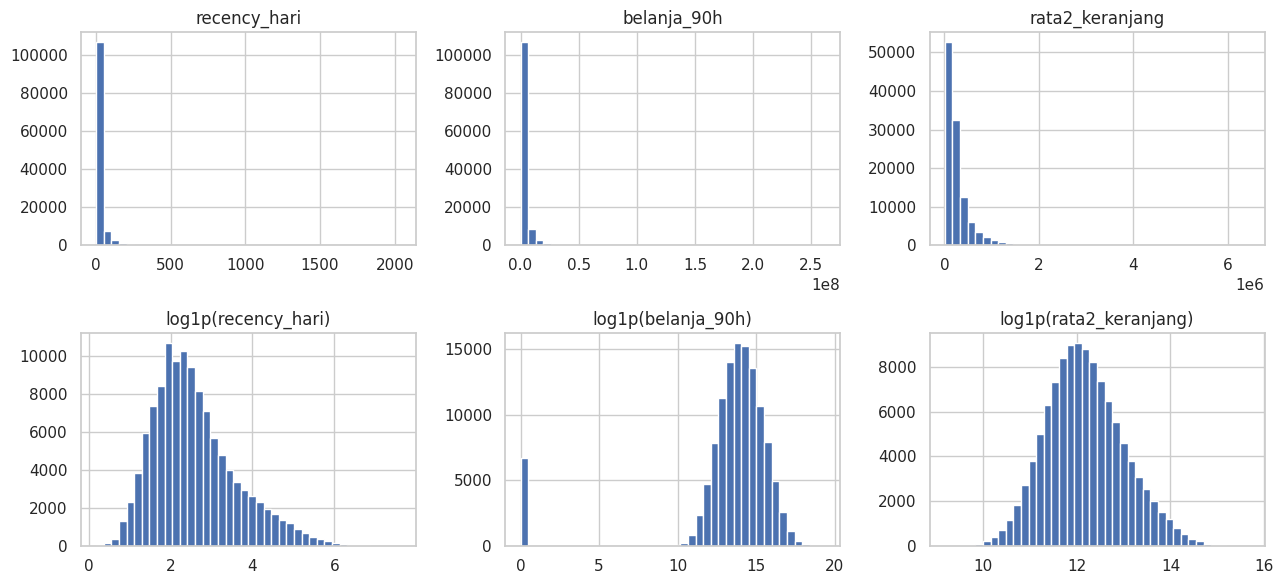

,fitur 1,fitur 2,korelasi
61,belanja_90h,belanja_30h,0.926
42,frekuensi_90h,frekuensi_30h,0.926
205,sesi_per_minggu,klik_iklan_30h,0.889
247,wishlist,klik_iklan_30h,0.862
204,sesi_per_minggu,wishlist,0.811
31,frekuensi_90h,ulasan_90h,0.806
197,ulasan_90h,frekuensi_30h,0.746
34,frekuensi_90h,rasio_konversi,0.692
22,frekuensi_90h,belanja_90h,0.669
224,rasio_konversi,frekuensi_30h,0.640


perangkat
android    64.8
ios        26.4
web         8.8


In [5]:
# Skewness (fitur numerik dan anonim)
sk = df[KOL_NUM + KOL_ANON].skew().sort_values(ascending=False)
display(sk.round(2).head(15).to_frame("skewness"))

# Outlier IQR
def persen_iqr(x):
    q1, q3 = x.quantile([0.25, 0.75]); i = q3 - q1
    return ((x < q1 - 1.5 * i) | (x > q3 + 1.5 * i)).mean() * 100
out = df[KOL_NUM + KOL_ANON].apply(persen_iqr).sort_values(ascending=False)
display(out.round(2).head(12).to_frame("outlier IQR (%)"))

# Bentuk distribusi sebelum dan sesudah log1p
fig, ax = plt.subplots(2, 3, figsize=(13, 6))
for j, c in enumerate(["recency_hari", "belanja_90h", "rata2_keranjang"]):
    df[c].hist(bins=40, ax=ax[0, j]); ax[0, j].set_title(c)
    np.log1p(df[c]).hist(bins=40, ax=ax[1, j]); ax[1, j].set_title(f"log1p({c})")
plt.tight_layout(); plt.show()

# Pasangan fitur paling berkorelasi (tanpa kolom anonim)
kor = df[KOL_NUM].corr()
atas = kor.where(np.triu(np.ones(kor.shape), 1).astype(bool)).stack().reset_index()
atas.columns = ["fitur 1", "fitur 2", "korelasi"]
display(atas.reindex(atas["korelasi"].abs().sort_values(ascending=False).index).head(10).round(3))

print(df["perangkat"].value_counts(normalize=True).mul(100).round(1).to_string())

Temuan run sebelumnya: fitur RFM sangat miring ke kanan (median `belanja_90h` sekitar 1,14 juta, maksimum 261,8 juta); `belanja_30h`/`frekuensi_30h` berkorelasi 0,93 dengan versi 90 hari; `n04` dan `n11` berkisar -500 sampai 500 (nilai ekstrem). Kolom `n01`-`n15` tidak dianggap bermakna sebelum diuji di bagian 4.

## 3. Preprocessing (poin a)

| Masalah | Penanganan |
|---|---|
| Skala berbeda | `StandardScaler` setelah transformasi |
| Skew | `log1p` untuk fitur non-negatif dengan skewness > 1 |
| Kompositional (porsi kategori, porsi jam) | zero replacement lalu CLR, per kelompok |
| Kategorik (`perangkat`) | one-hot |
| Missing (`rata2_keranjang`) | indikator kosong + imputasi median |
| Outlier | dipertahankan, di-winsorize 0,5% tiap ekor agar tidak mendominasi jarak |

In [6]:
# 1) Missing value: indikator + median
med_keranjang = df["rata2_keranjang"].median()

# 2) Skew: log1p bila skewness > 1 dan nilai tidak negatif
sk_num = df[KOL_NUM].skew()
LOG_COLS = [c for c in KOL_NUM if sk_num[c] > 1 and df[c].min() >= 0]
print("Fitur di-log1p:", LOG_COLS)

F = pd.DataFrame(index=df.index)
for c in KOL_NUM:
    x = df[c].astype(float)
    if c == "rata2_keranjang":
        F["rata2_keranjang_kosong"] = x.isnull().astype(float)
        x = x.fillna(med_keranjang)
    F[c] = np.log1p(x) if c in LOG_COLS else x

# 3) Kompositional: zero replacement multiplikatif lalu CLR
def clr(M):
    M = M.to_numpy(float)
    d = M.shape[1]
    s = M.sum(axis=1, keepdims=True)
    P = np.where(s > 0, M / np.where(s > 0, s, 1), 1.0 / d)      # tutup ke jumlah 1
    nol = (P == 0)
    delta = 0.65 * P[P > 0].min()
    P = np.where(nol, delta, P * (1 - nol.sum(axis=1, keepdims=True) * delta))
    L = np.log(P)
    return L - L.mean(axis=1, keepdims=True)

for kol in (KOL_KAT, KOL_JAM):
    C = clr(df[kol])
    for j, c in enumerate(kol):
        F["clr_" + c] = C[:, j]

# 4) Kategorik: one-hot
F = pd.concat([F, pd.get_dummies(df["perangkat"], prefix="perangkat", dtype=float)], axis=1)

# 5) Kolom anonim: hanya kandidat, diperlakukan sama pada tahap winsorize dan standardisasi
ALL = pd.concat([F, df[KOL_ANON].astype(float)], axis=1)

# 6) Outlier: winsorize, lalu standardisasi
lo, hi = ALL.quantile(WINS_P), ALL.quantile(1 - WINS_P)
persen_clip = (ALL.lt(lo, axis=1) | ALL.gt(hi, axis=1)).mean().mean() * 100
ALL = ALL.clip(lower=lo, upper=hi, axis=1)
S_all = pd.DataFrame(StandardScaler().fit_transform(ALL), columns=ALL.columns, index=ALL.index)

print(f"\nMatriks fitur kandidat: {S_all.shape} | nilai yang di-clip: {persen_clip:.2f}%")
display(pd.DataFrame({"skew asli": df[LOG_COLS].skew(), "skew setelah log1p": F[LOG_COLS].skew()}).round(2))

Fitur di-log1p: ['recency_hari', 'frekuensi_90h', 'belanja_90h', 'rata2_keranjang', 'item_per_pesanan', 'persen_paylater', 'retur_90h', 'ulasan_90h', 'sesi_per_minggu', 'durasi_sesi_menit', 'rasio_konversi', 'lama_member_bulan', 'jumlah_alamat', 'wishlist', 'klik_iklan_30h', 'belanja_30h', 'frekuensi_30h']

Matriks fitur kandidat: (120000, 62) | nilai yang di-clip: 0.74%


,skew asli,skew setelah log1p
recency_hari,7.94,0.82
frekuensi_90h,3.53,-0.18
belanja_90h,7.47,-2.99
rata2_keranjang,3.57,0.30
item_per_pesanan,3.48,0.77
persen_paylater,1.32,1.04
retur_90h,2.82,0.82
ulasan_90h,2.95,0.60
sesi_per_minggu,9.19,1.62
durasi_sesi_menit,1.59,-0.43


`S_all` berisi semua fitur kandidat yang sudah distandardisasi (termasuk `n01`-`n15`); seleksi dilakukan di bagian berikut.

## 4. Seleksi Fitur (poin b)

Tiga langkah dengan bukti angka:
1. **Redundansi**: pasangan fitur dengan |korelasi| >= `R_MAX` hanya diwakili satu (RFM inti tidak dibuang).
2. **Relevansi**: seberapa besar varians sebuah fitur dijelaskan oleh cluster (eta kuadrat), dari K-Means pilot pada K = 4, 6, 8. Diulang sampai himpunan fitur tidak berubah. `n01`-`n15` ikut diuji sebagai kandidat tetapi tidak ikut membentuk cluster pilot putaran pertama.
3. **Ablasi**: membandingkan hasil clustering dengan beberapa himpunan fitur.

In [7]:
# Langkah 1: redundansi
PROTEK = {"recency_hari", "frekuensi_90h", "belanja_90h"}          # RFM inti
fitur_dasar = [c for c in S_all.columns if c not in KOL_ANON]

C = S_all[fitur_dasar].corr().abs()
rata_kor = C.where(~np.eye(len(C), dtype=bool)).mean()
pasangan = sorted(((C.loc[a, b], a, b) for a, b in combinations(fitur_dasar, 2)
                   if C.loc[a, b] >= R_MAX), reverse=True)

dibuang = {}
for r, a, b in pasangan:
    if a in dibuang or b in dibuang or (a in PROTEK and b in PROTEK):
        continue
    if a in PROTEK:   d, k = b, a
    elif b in PROTEK: d, k = a, b
    else:             d, k = (a, b) if rata_kor[a] > rata_kor[b] else (b, a)
    dibuang[d] = (k, round(r, 3))

if dibuang:
    display(pd.DataFrame(dibuang, index=["diwakili oleh", "|korelasi|"]).T)
else:
    print("Tidak ada pasangan dengan |korelasi| >=", R_MAX)

kandidat = [c for c in fitur_dasar if c not in dibuang]
print("Kandidat setelah langkah 1:", len(kandidat), "fitur")

,diwakili oleh,|korelasi|
belanja_30h,belanja_90h,0.994
rata2_keranjang_kosong,belanja_90h,0.929
frekuensi_30h,frekuensi_90h,0.864
perangkat_ios,perangkat_android,0.813


Kandidat setelah langkah 1: 43 fitur


In [8]:
# Langkah 2: relevansi (eta kuadrat), iteratif
def eta2(X, lab):
    mu = X.mean(axis=0)
    sst = ((X - mu) ** 2).sum(axis=0)
    ssb = np.zeros(X.shape[1])
    for k in np.unique(lab):
        m = lab == k
        ssb += m.sum() * (X[m].mean(axis=0) - mu) ** 2
    return ssb / sst

idx_sel = np.random.default_rng(SEED).choice(len(S_all), min(SEL_N, len(S_all)), replace=False)
S_sub = S_all.iloc[idx_sel]
terpilih = list(kandidat)

for putaran in range(1, 4):
    Xp = S_sub[terpilih].to_numpy()
    e = [eta2(S_sub.to_numpy(), KMeans(k, n_init=3, random_state=SEED).fit_predict(Xp)) for k in K_PILOT]
    eta_df = pd.Series(np.mean(e, axis=0), index=S_sub.columns)
    baru = [c for c in S_all.columns if (c in kandidat or c in KOL_ANON) and eta_df[c] >= ETA2_MIN]
    if len(baru) < 5:
        baru = eta_df[kandidat].nlargest(10).index.tolist()
    print(f"Putaran {putaran}: {len(terpilih)} fitur -> {len(baru)} fitur terpilih")
    if set(baru) == set(terpilih):
        break
    terpilih = [c for c in S_all.columns if c in baru]

FITUR = [c for c in S_all.columns if c in terpilih]

tab = pd.DataFrame({"eta2": eta_df.round(4)})
tab["status"] = np.where(tab.index.isin(FITUR), "dipilih",
                 np.where(tab.index.isin(list(dibuang)), "dibuang: redundan", "dibuang: eta2 rendah"))
tab["kelompok"] = np.where(tab.index.isin(KOL_ANON), "anonim", "perilaku")
display(tab.sort_values("eta2", ascending=False))

n_dipilih = [c for c in FITUR if c in KOL_ANON]
print(f"Fitur terpilih: {len(FITUR)} | kolom anonim terpilih: {len(n_dipilih)}")
print(f"eta2 maksimum kolom anonim: {eta_df[KOL_ANON].max():.4f} (ambang {ETA2_MIN})")
for t in (0.01, 0.02, 0.05):
    print(f"  ambang {t}: {(eta_df[kandidat] >= t).sum()} fitur perilaku lolos")

Putaran 1: 43 fitur -> 32 fitur terpilih
Putaran 2: 32 fitur -> 32 fitur terpilih


,eta2,status,kelompok
perangkat_web,0.5870,dipilih,perilaku
belanja_90h,0.5336,dipilih,perilaku
belanja_30h,0.5313,dibuang: redundan,perilaku
frekuensi_90h,0.5264,dipilih,perilaku
rata2_keranjang_kosong,0.4574,dibuang: redundan,perilaku
...,...,...,...
n11,0.0001,dibuang: eta2 rendah,anonim
n03,0.0000,dibuang: eta2 rendah,anonim
n09,0.0000,dibuang: eta2 rendah,anonim
n08,0.0000,dibuang: eta2 rendah,anonim


Fitur terpilih: 32 | kolom anonim terpilih: 0
eta2 maksimum kolom anonim: 0.0003 (ambang 0.02)
  ambang 0.01: 33 fitur perilaku lolos
  ambang 0.02: 32 fitur perilaku lolos
  ambang 0.05: 25 fitur perilaku lolos


In [9]:
# Bukti tambahan untuk kolom anonim: korelasi dengan fitur perilaku
kor_n = S_all[KOL_ANON + fitur_dasar].corr().loc[KOL_ANON, fitur_dasar].abs().max(axis=1)
display(kor_n.round(3).to_frame("|korelasi| maks dengan fitur perilaku").T)

,n01,n02,n03,n04,n05,n06,n07,n08,n09,n10,n11,n12,n13,n14,n15
|korelasi| maks dengan fitur perilaku,0.008,0.008,0.007,0.006,0.008,0.007,0.008,0.008,0.007,0.005,0.004,0.008,0.009,0.008,0.007


In [10]:
# Langkah 3: ablasi himpunan fitur (K = 6, pada sampel seleksi)
K_ABL = 6
RFM5 = ["recency_hari", "frekuensi_90h", "belanja_90h", "rata2_keranjang", "item_per_pesanan"]
himpunan = {
    "RFM saja": RFM5,
    "Terpilih": FITUR,
    "Semua non-anonim": fitur_dasar,
    "Terpilih + n01-n15": list(dict.fromkeys(FITUR + KOL_ANON)),
}
lab_abl = {nama: KMeans(K_ABL, n_init=3, random_state=SEED).fit_predict(S_sub[kol].to_numpy())
           for nama, kol in himpunan.items()}
ruang_ref = S_sub[FITUR].to_numpy()          # ruang terpilih sebagai pembanding bersama
baris = []
for nama, kol in himpunan.items():
    baris.append({"himpunan fitur": nama, "jumlah fitur": len(kol),
                  "ARI vs Terpilih": adjusted_rand_score(lab_abl["Terpilih"], lab_abl[nama]),
                  "silhouette di ruang Terpilih": silhouette_score(ruang_ref, lab_abl[nama],
                                                                  sample_size=10000, random_state=SEED)})
display(pd.DataFrame(baris).set_index("himpunan fitur").round(3))

,jumlah fitur,ARI vs Terpilih,silhouette di ruang Terpilih
himpunan fitur,,,
RFM saja,5,0.252,0.035
Terpilih,32,1.000,0.079
Semua non-anonim,47,0.683,0.076
Terpilih + n01-n15,47,0.608,0.061


Matriks akhir: fitur terpilih diproyeksikan dengan PCA (varians 99%). Ini membuang arah redundan (CLR berjumlah nol, sehingga kovarians singular) tanpa mengubah jarak secara berarti, dan membuat GMM stabil.

In [11]:
X_sel = S_all[FITUR].to_numpy()
pca = PCA(n_components=PCA_VAR, svd_solver="full", random_state=SEED)
Z = pca.fit_transform(X_sel)
N = len(Z)
print(f"Fitur terpilih: {X_sel.shape[1]} -> komponen PCA: {Z.shape[1]} (varians {pca.explained_variance_ratio_.sum():.3f})")

Fitur terpilih: 32 -> komponen PCA: 30 (varians 0.997)


## 5. Perbandingan Metode (poin c)

Tiga metode: **K-Means**, **Gaussian Mixture (GMM)**, dan **Agglomerative (Ward)**. Agglomerative dijalankan pada sampel `CAP_AGG`, lalu label diperluas ke semua pelanggan dengan KNN. GMM pada sweep memakai sampel `CAP_GMM`. Metrik dihitung pada sampel evaluasi yang sama untuk semua metode.

In [12]:
idx_eval = np.random.default_rng(SEED).choice(N, min(N_EVAL, N), replace=False)

def metrik(lab):
    ukuran = np.unique(lab, return_counts=True)[1]
    out = {"min_share": ukuran.min() / N * 100}
    le = lab[idx_eval]
    if len(np.unique(le)) < 2:
        return {**out, "silhouette": np.nan, "db": np.nan, "ch": np.nan}
    Ze = Z[idx_eval]
    return {**out, "silhouette": silhouette_score(Ze, le),
            "db": davies_bouldin_score(Ze, le), "ch": calinski_harabasz_score(Ze, le)}

t0 = time.time()
hasil, inertia = [], {}

# K-Means
for K in K_RANGE:
    km = KMeans(K, n_init=5, random_state=SEED).fit(Z)
    inertia[K] = km.inertia_
    hasil.append({"metode": "KMeans", "K": K, **metrik(km.labels_)})
print(f"K-Means selesai ({time.time()-t0:.0f} dtk)")

# Agglomerative (Ward) pada sampel, dipropagasi dengan KNN
sub_agg = np.random.default_rng(SEED).choice(N, min(CAP_AGG, N), replace=False)
link_agg = hierarchy.linkage(Z[sub_agg], method="ward")
for K in K_RANGE:
    lab_sub = hierarchy.fcluster(link_agg, K, criterion="maxclust") - 1
    lab = KNeighborsClassifier(n_neighbors=15).fit(Z[sub_agg], lab_sub).predict(Z)
    hasil.append({"metode": "Agglomerative", "K": K, **metrik(lab)})
print(f"Agglomerative selesai ({time.time()-t0:.0f} dtk)")

# GMM: BIC untuk dua tipe kovarians, lalu metrik untuk tipe terbaik
sub_gmm = np.random.default_rng(SEED).choice(N, min(CAP_GMM, N), replace=False)
gmm_model, bic_rows = {}, []
for cov in ("full", "diag"):
    for K in K_RANGE:
        g = GaussianMixture(K, covariance_type=cov, n_init=1, max_iter=150,
                            reg_covar=1e-5, random_state=SEED).fit(Z[sub_gmm])
        gmm_model[(cov, K)] = g
        bic_rows.append({"cov": cov, "K": K, "BIC": g.bic(Z[sub_gmm]), "AIC": g.aic(Z[sub_gmm])})
bic = pd.DataFrame(bic_rows)
COV_GMM = bic.groupby("cov")["BIC"].min().idxmin()
for K in K_RANGE:
    hasil.append({"metode": "GMM", "K": K, **metrik(gmm_model[(COV_GMM, K)].predict(Z))})
print(f"GMM selesai ({time.time()-t0:.0f} dtk) | tipe kovarians terbaik (BIC): {COV_GMM}")

hasil = pd.DataFrame(hasil)
display(hasil.pivot(index="K", columns="metode", values="silhouette").round(3).add_prefix("silhouette "))

K-Means selesai (45 dtk)
Agglomerative selesai (170 dtk)
GMM selesai (331 dtk) | tipe kovarians terbaik (BIC): full


metode,silhouette Agglomerative,silhouette GMM,silhouette KMeans
K,,,
2,0.068,0.120,0.084
3,0.079,0.114,0.092
4,0.091,0.092,0.076
5,0.097,0.057,0.080
6,0.084,0.060,0.079
7,0.075,0.047,0.079
8,0.066,0.018,0.074
9,0.064,0.027,0.078
10,0.064,0.031,0.075


## 6. Jumlah Cluster (poin d)

Kriteria: **silhouette**, **Davies-Bouldin**, **BIC** (GMM), elbow inertia, dan **stabilitas** (ARI antar-run subsampling, K-Means). K final dipilih dari K >= `K_MIN` yang stabil (ARI >= `STAB_MIN`) dan tidak memiliki cluster di bawah `MIN_SHARE`%, dengan silhouette tertinggi. BIC dan elbow dipakai sebagai pemeriksa silang.

In [13]:
# Fungsi umum: latih metode pada data (sub)sampel, kembalikan fungsi predict untuk semua titik
def fit_metode(nama, Zfit, K, seed, cap_gmm=CAP_GMM, cap_agg=CAP_AGG):
    rs = np.random.default_rng(seed)
    if nama == "KMeans":
        return KMeans(K, n_init=3, random_state=seed).fit(Zfit).predict
    if nama == "GMM":
        sub = Zfit if len(Zfit) <= cap_gmm else Zfit[rs.choice(len(Zfit), cap_gmm, replace=False)]
        return GaussianMixture(K, covariance_type=COV_GMM, n_init=1, max_iter=150,
                               reg_covar=1e-5, random_state=seed).fit(sub).predict
    if nama == "Agglomerative":
        sub = Zfit if len(Zfit) <= cap_agg else Zfit[rs.choice(len(Zfit), cap_agg, replace=False)]
        lab = hierarchy.fcluster(hierarchy.linkage(sub, method="ward"), K, criterion="maxclust") - 1
        return KNeighborsClassifier(n_neighbors=15).fit(sub, lab).predict
    raise ValueError(nama)

def stabilitas(nama, K, B, frac=FRAC_BOOT, seed=SEED):
    rs = np.random.default_rng(seed)
    labs = []
    for b in range(B):
        idx = rs.choice(N, int(frac * N), replace=False)
        labs.append(fit_metode(nama, Z[idx], K, seed + b + 1)(Z))
    ari = np.array([adjusted_rand_score(a, b) for a, b in combinations(labs, 2)])
    return ari, labs

# Stabilitas K-Means untuk setiap K
t0 = time.time()
stab_K = pd.Series({K: stabilitas("KMeans", K, 5)[0].mean() for K in K_RANGE}, name="ARI antar-run")
print(f"Stabilitas per K selesai ({time.time()-t0:.0f} dtk)")

Stabilitas per K selesai (71 dtk)


,inertia,silhouette,db,ch,min_share,stabilitas
K,,,,,,
2,3496983.227,0.084,3.124,937.854,40.052,0.996
3,3278622.797,0.092,2.798,834.997,21.826,0.997
4,3173784.920,0.076,2.933,682.817,14.702,0.875
5,3091400.607,0.080,2.612,598.918,1.500,0.879
6,3009649.859,0.079,2.880,545.078,7.912,0.739
7,2934586.284,0.079,2.797,506.553,5.557,0.814
8,2869021.436,0.074,2.761,478.359,5.549,0.837
9,2799600.317,0.078,2.634,463.565,1.500,0.911
10,2753974.933,0.075,2.757,436.645,1.500,0.945


K kandidat      : [3, 4, 5, 7, 8, 9, 10, 11, 12]
Silhouette      : K = 3
Davies-Bouldin  : K = 5
BIC (siku)      : K = 6
Inertia (siku)  : K = 6

K FINAL = 3
Catatan: siku BIC berbeda jauh dari K final; tinjau grafik dan pertimbangkan K_OVERRIDE.


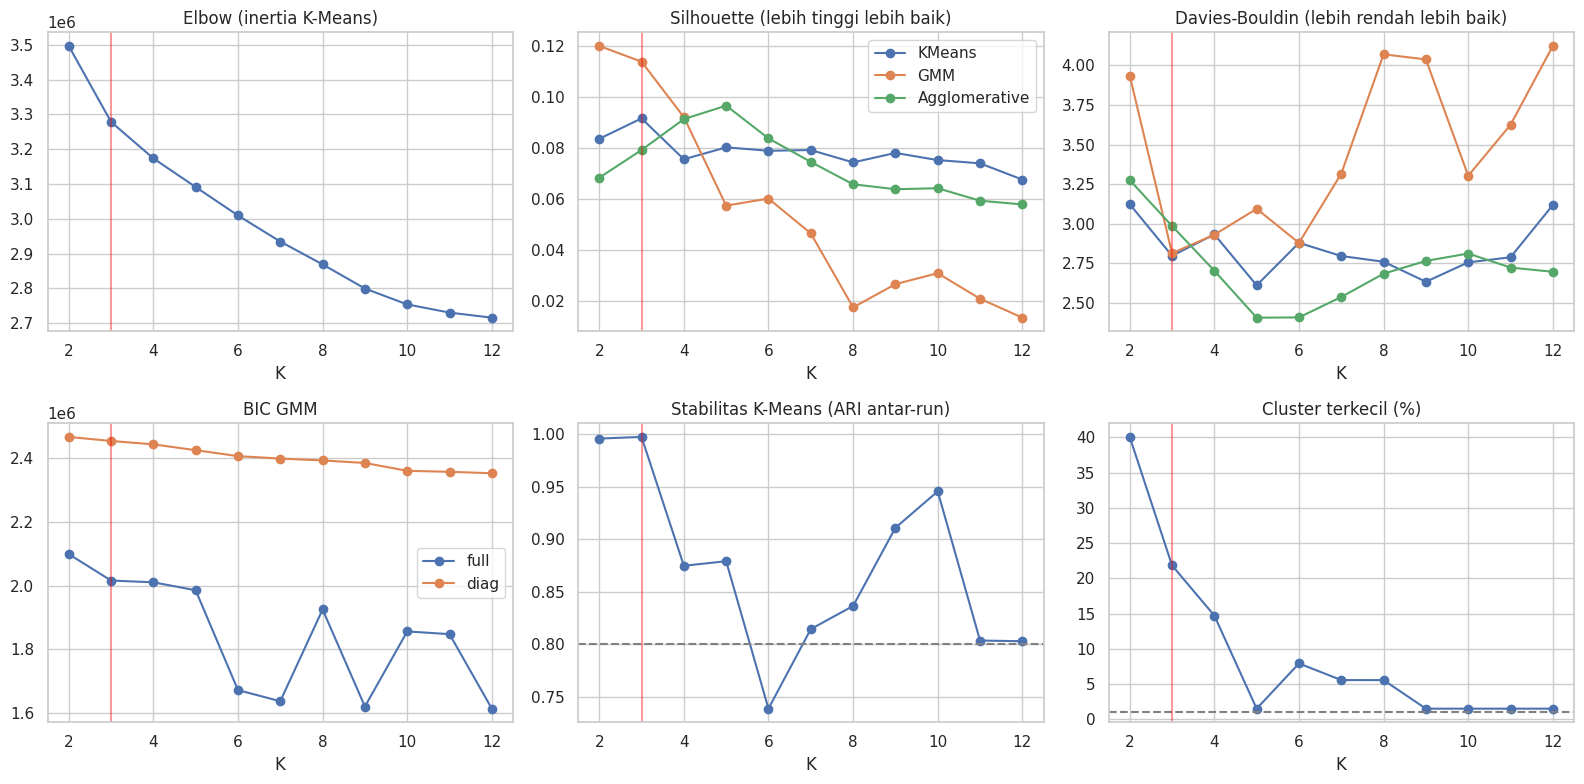

In [14]:
km_tab = hasil[hasil["metode"] == "KMeans"].set_index("K")
km_tab = km_tab.assign(inertia=pd.Series(inertia), stabilitas=stab_K)
bic_tab = bic[bic["cov"] == COV_GMM].set_index("K")["BIC"]

def siku(x, y):                       # titik terjauh dari garis lurus awal-akhir (kurva ternormalisasi)
    x = np.asarray(x, float); y = np.asarray(y, float)
    xn = (x - x.min()) / (x.max() - x.min()); yn = (y - y.min()) / (y.max() - y.min())
    dx, dy = xn[-1] - xn[0], yn[-1] - yn[0]
    jarak = np.abs(dy * (xn - xn[0]) - dx * (yn - yn[0])) / np.hypot(dx, dy)
    return int(x[np.argmax(jarak)])

kand_K = [K for K in K_RANGE if K >= K_MIN and km_tab.loc[K, "stabilitas"] >= STAB_MIN
          and km_tab.loc[K, "min_share"] >= MIN_SHARE]
if not kand_K:
    print("Tidak ada K yang memenuhi semua syarat; memakai K dengan stabilitas tertinggi.")
    kand_K = [int(km_tab.loc[K_MIN:, "stabilitas"].idxmax())]

K_SIL = max(kand_K, key=lambda K: km_tab.loc[K, "silhouette"])
K_DB = min(kand_K, key=lambda K: km_tab.loc[K, "db"])
K_BIC = siku(list(K_RANGE), bic_tab.loc[list(K_RANGE)].values)
K_ELBOW = siku(list(K_RANGE), km_tab["inertia"].values)
K_FINAL = int(K_OVERRIDE) if K_OVERRIDE else K_SIL

display(km_tab[["inertia", "silhouette", "db", "ch", "min_share", "stabilitas"]].round(3))
print(f"K kandidat      : {kand_K}")
print(f"Silhouette      : K = {K_SIL}")
print(f"Davies-Bouldin  : K = {K_DB}")
print(f"BIC (siku)      : K = {K_BIC}")
print(f"Inertia (siku)  : K = {K_ELBOW}")
print(f"\nK FINAL = {K_FINAL}")
if abs(K_BIC - K_FINAL) > 2:
    print("Catatan: siku BIC berbeda jauh dari K final; tinjau grafik dan pertimbangkan K_OVERRIDE.")

fig, ax = plt.subplots(2, 3, figsize=(16, 8))
ax = ax.ravel()
ax[0].plot(km_tab.index, km_tab["inertia"], "o-"); ax[0].set_title("Elbow (inertia K-Means)")
for m in ("KMeans", "GMM", "Agglomerative"):
    d = hasil[hasil["metode"] == m]
    ax[1].plot(d["K"], d["silhouette"], "o-", label=m); ax[2].plot(d["K"], d["db"], "o-", label=m)
ax[1].set_title("Silhouette (lebih tinggi lebih baik)"); ax[1].legend()
ax[2].set_title("Davies-Bouldin (lebih rendah lebih baik)")
for cov in ("full", "diag"):
    d = bic[bic["cov"] == cov]; ax[3].plot(d["K"], d["BIC"], "o-", label=cov)
ax[3].set_title("BIC GMM"); ax[3].legend()
ax[4].plot(stab_K.index, stab_K.values, "o-"); ax[4].axhline(STAB_MIN, ls="--", c="gray")
ax[4].set_title("Stabilitas K-Means (ARI antar-run)")
ax[5].plot(km_tab.index, km_tab["min_share"], "o-"); ax[5].axhline(MIN_SHARE, ls="--", c="gray")
ax[5].set_title("Cluster terkecil (%)")
for a in ax:
    a.axvline(K_FINAL, color="red", alpha=0.4); a.set_xlabel("K")
plt.tight_layout(); plt.show()

## 7. Stabilitas dan Pemilihan Metode (poin e)

Setiap metode dijalankan `B_BOOT` kali pada subsampel 80% data tanpa pengembalian, lalu label diprediksi untuk seluruh pelanggan dan dibandingkan antar-run dengan **ARI**. Metode final dipilih dari rata-rata peringkat silhouette, Davies-Bouldin, dan stabilitas.

In [15]:
t0 = time.time()
lab_m, ari_run, baris = {}, {}, []
for nama in ("KMeans", "GMM", "Agglomerative"):
    lab_m[nama] = fit_metode(nama, Z, K_FINAL, SEED, cap_gmm=N)(Z)           # model pada seluruh data
    ari_run[nama], labs = stabilitas(nama, K_FINAL, B_BOOT)
    ari_full = [adjusted_rand_score(lab_m[nama], l) for l in labs]
    baris.append({"metode": nama, **metrik(lab_m[nama]),
                  "ARI antar-run (rata2)": ari_run[nama].mean(), "ARI antar-run (sd)": ari_run[nama].std(),
                  "ARI antar-run (min)": ari_run[nama].min(), "ARI run vs model penuh": np.mean(ari_full)})
    print(f"{nama} selesai ({time.time()-t0:.0f} dtk)")

banding = pd.DataFrame(baris).set_index("metode")
peringkat = pd.concat([banding["silhouette"].rank(ascending=False),
                       banding["db"].rank(ascending=True),
                       banding["ARI antar-run (rata2)"].rank(ascending=False)], axis=1).mean(axis=1)
METODE_FINAL = METODE_OVERRIDE or peringkat.sort_values(kind="stable").index[0]

display(banding.round(3))
print("Rata-rata peringkat (lebih kecil lebih baik):", peringkat.round(2).to_dict())
print("METODE FINAL =", METODE_FINAL)

# Kemiripan antar-metode pada K final
ari_mat = pd.DataFrame({a: {b: adjusted_rand_score(lab_m[a], lab_m[b]) for b in lab_m} for a in lab_m})
display(ari_mat.round(3))

KMeans selesai (10 dtk)
GMM selesai (64 dtk)
Agglomerative selesai (233 dtk)


,min_share,silhouette,db,ch,ARI antar-run (rata2),ARI antar-run (sd),ARI antar-run (min),ARI run vs model penuh
metode,,,,,,,,
KMeans,21.826,0.092,2.798,834.997,0.997,0.001,0.994,0.998
GMM,5.613,0.114,2.815,402.597,0.940,0.120,0.701,0.970
Agglomerative,17.320,0.079,2.987,721.936,0.782,0.106,0.537,0.833


Rata-rata peringkat (lebih kecil lebih baik): {'KMeans': 1.33, 'GMM': 1.67, 'Agglomerative': 3.0}
METODE FINAL = KMeans


,KMeans,GMM,Agglomerative
KMeans,1.000,0.052,0.724
GMM,0.052,1.000,0.059
Agglomerative,0.724,0.059,1.000


KMeans, K = 3, 10 run subsampling 80% (45 pasangan)
ARI antar-run: rata-rata 0.997 | sd 0.001 | min 0.994 | maks 0.998


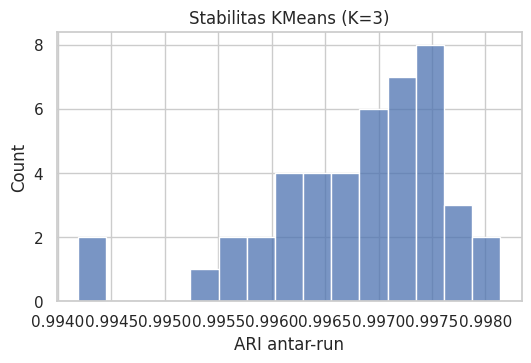

In [16]:
# Laporan stabilitas metode final: ARI antar pasangan run
a = ari_run[METODE_FINAL]
print(f"{METODE_FINAL}, K = {K_FINAL}, {B_BOOT} run subsampling {int(FRAC_BOOT*100)}% ({len(a)} pasangan)")
print(f"ARI antar-run: rata-rata {a.mean():.3f} | sd {a.std():.3f} | min {a.min():.3f} | maks {a.max():.3f}")

plt.figure(figsize=(6, 3.5))
sns.histplot(a, bins=15); plt.xlabel("ARI antar-run"); plt.title(f"Stabilitas {METODE_FINAL} (K={K_FINAL})")
plt.show()

## 8. Anomali (poin g)

Pelanggan yang tidak cocok dengan segmen manapun ditandai **-1** memakai Isolation Forest pada ruang fitur terpilih. Hanya `ANOMALY_FRAC` (1%) skor teratas yang ditandai: anomali referensi tidak ikut dihitung dalam ARI, sehingga menandai terlalu banyak pelanggan biasa justru menurunkan skor.

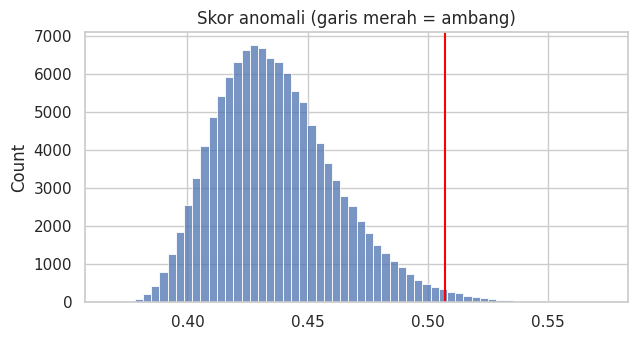

Anomali (-1): 1,200 pelanggan (1.00%)


col_0,normal (%),anomali (%)
cluster awal,,
0,99.16,0.84
1,99.21,0.79
2,98.33,1.67


,recency_hari,frekuensi_90h,belanja_90h,rata2_keranjang,item_per_pesanan,retur_90h
anomali,15.0,4.0,607300.0,196100.0,2.0,1.0
normal,10.0,7.0,1140400.0,183800.0,2.0,0.0


In [17]:
# Label cluster final, diurutkan dari cluster terbesar
urutan = pd.Series(lab_m[METODE_FINAL]).value_counts().index
peta = {lama: baru for baru, lama in enumerate(urutan)}
cluster_awal = pd.Series(lab_m[METODE_FINAL]).map(peta).to_numpy()

# Anomali
iso = IsolationForest(n_estimators=300, random_state=SEED, n_jobs=-1).fit(Z)
skor_anom = -iso.score_samples(Z)                     # makin besar makin tidak biasa
ambang = np.quantile(skor_anom, 1 - ANOMALY_FRAC)
anom = skor_anom >= ambang

cluster_final = cluster_awal.copy()
cluster_final[anom] = -1
hasil_clustering = df.copy()
hasil_clustering["cluster"] = cluster_final

plt.figure(figsize=(7, 3.5))
sns.histplot(skor_anom, bins=60); plt.axvline(ambang, color="red")
plt.title("Skor anomali (garis merah = ambang)"); plt.show()

print(f"Anomali (-1): {anom.sum():,} pelanggan ({anom.mean()*100:.2f}%)")
display(pd.crosstab(cluster_awal, anom, normalize="index").mul(100).round(2)
        .rename(columns={False: "normal (%)", True: "anomali (%)"}).rename_axis("cluster awal"))

kunci = ["recency_hari", "frekuensi_90h", "belanja_90h", "rata2_keranjang", "item_per_pesanan", "retur_90h"]
display(df[kunci].groupby(np.where(anom, "anomali", "normal")).median().round(1))

## 9. Profil dan Aksi Segmen (poin f)

Profil memakai nilai asli (median) dan z-score rata-rata cluster pada fitur ter-standardisasi. Nama dan aksi di bawah dibuat otomatis dari pola Recency-Frequency-Monetary dan fitur paling menonjol; **tinjau dan sesuaikan dengan tabel profil sebelum masuk laporan**.

    jumlah pelanggan  persen
-1              1200    1.00
 0             48067   40.06
 1             44979   37.48
 2             25754   21.46


cluster,-1,0,1,2
recency_hari,15.0,9.2,6.6,46.5
frekuensi_90h,4.0,7.0,12.0,1.0
belanja_90h,607300.0,822400.0,3659800.0,243050.0
rata2_keranjang,196100.0,123800.0,313600.0,175400.0
item_per_pesanan,2.0,2.0,3.0,2.0
retur_90h,1.0,1.0,0.0,0.0
ulasan_90h,0.0,1.0,2.0,0.0
sesi_per_minggu,17.92,6.93,5.77,2.23
rasio_konversi,0.01,0.08,0.16,0.05
lama_member_bulan,17.2,11.2,18.9,23.0


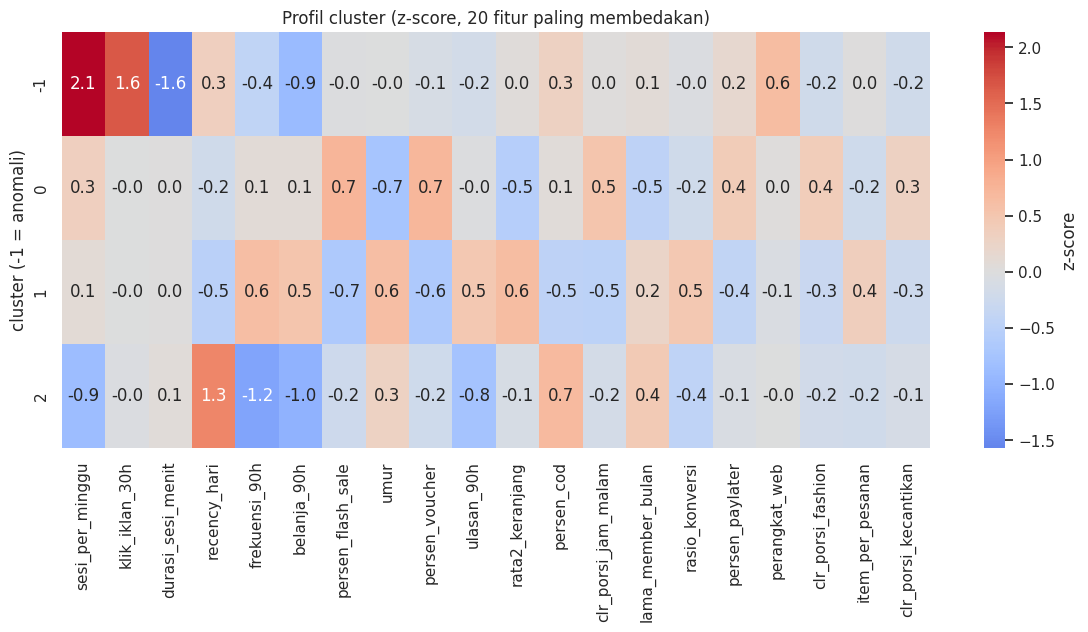

In [18]:
ukuran = pd.Series(cluster_final).value_counts().sort_index()
print(ukuran.to_frame("jumlah pelanggan").assign(persen=lambda t: (t["jumlah pelanggan"] / N * 100).round(2)))

# Profil pada skala asli
hc = hasil_clustering
kol_median = ["recency_hari", "frekuensi_90h", "belanja_90h", "rata2_keranjang", "item_per_pesanan",
              "retur_90h", "ulasan_90h", "sesi_per_minggu", "rasio_konversi", "lama_member_bulan", "umur"]
kol_persen = ["persen_voucher", "persen_flash_sale", "persen_paylater", "persen_cod"]
prof = hc.groupby("cluster")[kol_median].median()
prof = prof.join(hc.groupby("cluster")[kol_persen].mean())
prof["kategori_dominan"] = hc.groupby("cluster")[KOL_KAT].mean().idxmax(axis=1).str.replace("porsi_", "")
prof["jam_dominan"] = hc.groupby("cluster")[KOL_JAM].mean().idxmax(axis=1).str.replace("porsi_jam_", "")
prof = prof.join(pd.crosstab(hc["cluster"], hc["perangkat"], normalize="index").mul(100).add_prefix("%"))
display(prof.round(2).T)

# Profil relatif (z-score rata-rata cluster)
Zc = S_all.groupby(cluster_final).mean()
top = Zc.loc[:, [c for c in FITUR if c in Zc.columns]].var().nlargest(20).index
plt.figure(figsize=(14, 0.6 * len(Zc) + 3))
sns.heatmap(Zc[top], annot=True, fmt=".1f", cmap="coolwarm", center=0, cbar_kws={"label": "z-score"})
plt.title("Profil cluster (z-score, 20 fitur paling membedakan)"); plt.ylabel("cluster (-1 = anomali)")
plt.show()

In [19]:
# Nama dan aksi otomatis berdasarkan pola RFM + fitur paling menonjol
ATRIBUT = {
    "persen_flash_sale": ("responsif flash sale", "dorong notifikasi flash sale dan penawaran berbatas waktu"),
    "persen_voucher":    ("responsif voucher",    "kirim voucher personal sebagai pemicu transaksi"),
    "persen_paylater":   ("pengguna PayLater",    "tawarkan promo cicilan/PayLater"),
    "persen_cod":        ("pengguna COD",         "beri insentif pindah ke pembayaran digital"),
    "sesi_per_minggu":   ("sangat aktif di aplikasi", "gunakan push notification dan rekomendasi produk"),
    "wishlist":          ("banyak wishlist",      "ingatkan produk wishlist yang turun harga"),
    "klik_iklan_30h":    ("responsif iklan",      "perkuat retargeting iklan"),
    "retur_90h":         ("sering retur",         "perjelas deskripsi produk dan panduan ukuran"),
}
def atribut(f):
    if f in ATRIBUT: return ATRIBUT[f]
    if f.startswith("clr_porsi_jam_"):
        j = f.replace("clr_porsi_jam_", ""); return (f"belanja saat {j}", f"jadwalkan promo pada jam {j}")
    if f.startswith("clr_porsi_"):
        k = f.replace("clr_porsi_", "").replace("_", " "); return (f"condong ke {k}", f"kampanye kategori {k}")
    if f.startswith("perangkat_"):
        p = f.replace("perangkat_", ""); return (f"dominan {p}", f"optimalkan pengalaman di {p}")
    return (f"{f} tinggi", f"manfaatkan {f} dalam penargetan")

def nama_aksi(z):
    r, f, m = -z["recency_hari"], z["frekuensi_90h"], z["belanja_90h"]       # r > 0: baru bertransaksi
    if r > 0.3 and f > 0.5 and m > 0.5:
        return "Loyal bernilai tinggi", "program loyalti/VIP dan akses awal produk baru"
    if r < -0.3 and f < 0:
        return "Pasif berisiko churn", "kampanye win-back dengan voucher personal berbatas waktu"
    if m > 0.5 and f <= 0.5:
        return "Pembelanja besar jarang", "bundling produk bernilai tinggi dan pengingat pembelian ulang"
    if f > 0.5 and m <= 0.5:
        return "Sering belanja nilai kecil", "upsell lewat minimum belanja gratis ongkir dan paket hemat"
    if r > 0.3 and f < -0.3:
        return "Baru/pemula", "onboarding dan voucher pembelian kedua"
    return "Reguler", "cross-sell kategori favorit dan promosi musiman"

RFM_KOL = {"recency_hari", "frekuensi_90h", "belanja_90h", "rata2_keranjang_kosong"}
baris = []
for c in Zc.index:
    z = Zc.loc[c]
    if c == -1:
        baris.append({"cluster": -1, "ukuran (%)": round(ukuran[c] / N * 100, 2), "nama segmen": "Anomali",
                      "ciri menonjol": "pola belanja tidak cocok dengan segmen manapun",
                      "aksi pemasaran": "tinjau manual (verifikasi data/penipuan), jangan masuk kampanye massal"})
        continue
    nama, aksi = nama_aksi(z)
    kandidat_ciri = z[[f for f in FITUR if f in z.index and f not in RFM_KOL]]
    f_top = kandidat_ciri.idxmax() if kandidat_ciri.max() > 0.3 else None
    ciri = f"R={-z['recency_hari']:+.1f}, F={z['frekuensi_90h']:+.1f}, M={z['belanja_90h']:+.1f} (z)"
    if f_top:
        sifat, tambahan = atribut(f_top)
        nama, ciri, aksi = f"{nama}, {sifat}", ciri + f"; {sifat}", f"{aksi}; {tambahan}"
    baris.append({"cluster": c, "ukuran (%)": round(ukuran[c] / N * 100, 2),
                  "nama segmen": nama, "ciri menonjol": ciri, "aksi pemasaran": aksi})

profil_segmen = pd.DataFrame(baris).set_index("cluster")
pd.set_option("display.max_colwidth", 200)
display(profil_segmen)
profil_segmen.to_csv("profil_segmen.csv")

,ukuran (%),nama segmen,ciri menonjol,aksi pemasaran
cluster,,,,
-1,1.00,Anomali,pola belanja tidak cocok dengan segmen manapun,"tinjau manual (verifikasi data/penipuan), jangan masuk kampanye massal"
0,40.06,"Reguler, responsif flash sale","R=+0.2, F=+0.1, M=+0.1 (z); responsif flash sale",cross-sell kategori favorit dan promosi musiman; dorong notifikasi flash sale dan penawaran berbatas waktu
1,37.48,"Loyal bernilai tinggi, rata2_keranjang tinggi","R=+0.5, F=+0.6, M=+0.5 (z); rata2_keranjang tinggi",program loyalti/VIP dan akses awal produk baru; manfaatkan rata2_keranjang dalam penargetan
2,21.46,"Pasif berisiko churn, pengguna COD","R=-1.3, F=-1.2, M=-1.0 (z); pengguna COD",kampanye win-back dengan voucher personal berbatas waktu; beri insentif pindah ke pembayaran digital


## 10. Ekspor `cluster.csv`

Dua kolom (`id_pelanggan`, `cluster`), satu baris per pelanggan, `cluster` bilangan bulat, -1 untuk anomali. File dibaca ulang untuk validasi.

In [20]:
cluster_csv = pd.DataFrame({"id_pelanggan": df["id_pelanggan"], "cluster": cluster_final.astype(int)})
cluster_csv.to_csv("cluster.csv", index=False)

cek = pd.read_csv("cluster.csv")
print("Kolom        :", cek.columns.tolist())
print("Jumlah baris :", f"{len(cek):,}")
print("ID unik      :", f"{cek['id_pelanggan'].nunique():,}")
print("Nilai kosong :", int(cek.isnull().sum().sum()))
print("ID = data asli:", set(cek["id_pelanggan"]) == set(df["id_pelanggan"]))
print("Tipe cluster :", cek["cluster"].dtype)
print(cek["cluster"].value_counts().sort_index().to_string())

assert list(cek.columns) == ["id_pelanggan", "cluster"]
assert len(cek) == len(df) and cek["id_pelanggan"].is_unique
assert pd.api.types.is_integer_dtype(cek["cluster"])

try:
    from google.colab import files
    files.download("cluster.csv")
except Exception:
    print("\nTersimpan di folder kerja: cluster.csv")

Kolom        : ['id_pelanggan', 'cluster']
Jumlah baris : 120,000
ID unik      : 120,000
Nilai kosong : 0
ID = data asli: True
Tipe cluster : int64
cluster
-1     1200
 0    48067
 1    44979
 2    25754


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 11. Ringkasan dan Keterbatasan

In [21]:
a = ari_run[METODE_FINAL]
print(f"Fitur kandidat awal       : {len(fitur_dasar) + len(KOL_ANON)}")
print(f"Fitur terpilih            : {len(FITUR)} (kolom anonim terpilih: {len(n_dipilih)})")
print(f"Komponen PCA              : {Z.shape[1]}")
print(f"Metode / K final          : {METODE_FINAL} / {K_FINAL}")
print(f"Silhouette (sampel)       : {banding.loc[METODE_FINAL, 'silhouette']:.3f}")
print(f"ARI antar-run             : {a.mean():.3f} +/- {a.std():.3f} (min {a.min():.3f})")
print(f"Anomali (-1)              : {anom.sum():,} ({anom.mean()*100:.2f}%)")
print(f"Ukuran segmen (%)         :", (ukuran.drop(-1, errors='ignore') / N * 100).round(1).to_dict())

Fitur kandidat awal       : 62
Fitur terpilih            : 32 (kolom anonim terpilih: 0)
Komponen PCA              : 30
Metode / K final          : KMeans / 3
Silhouette (sampel)       : 0.092
ARI antar-run             : 0.997 +/- 0.001 (min 0.994)
Anomali (-1)              : 1,200 (1.00%)
Ukuran segmen (%)         : {0: 40.1, 1: 37.5, 2: 21.5}


**Keterbatasan**
- Tanpa label, kualitas dinilai dari kriteria internal dan stabilitas; kecocokan dengan segmen referensi tidak bisa diperiksa langsung.
- K dipilih dengan aturan (stabil, cluster tidak terlalu kecil, silhouette tertinggi); kriteria lain bisa menyarankan K berbeda, lihat bagian 6.
- Ambang seleksi fitur (`ETA2_MIN`, `R_MAX`) dan porsi anomali (`ANOMALY_FRAC`) adalah pilihan analis; hasil sensitivitasnya dicetak di bagian 4 dan 8.
- Seleksi fitur memakai cluster pilot, sehingga bersifat heuristik; ablasi di bagian 4 menjadi pemeriksanya.
- Agglomerative dan GMM pada sweep memakai sampel untuk efisiensi.

**Reproduksi:** letakkan `clustering.csv.gz` atau `data_uts_ml.zip` di folder kerja, lalu jalankan
`jupyter nbconvert --to notebook --execute Task_3_Clustering_ML.ipynb`. Seed dan versi library tercetak di bagian 0.